# Relationship between Caffeine Intake and Study Effectiveness

**Course:** Data Collection & Preparation  |  **Project type:** SIS  |  **Team:** <TeamName>  |  **Members:** <Name 1>, <Name 2>, <Name 3>

## Project goal
Apply the full data pipeline: **collect** (API + web scraping) → **clean** → **merge** → **explore (EDA)** → **visualize** → **conclude**.

## Research question
Do countries with higher caffeine intake per person show higher study effectiveness (learning outcomes)?

## Approach
Individual-level data on caffeine and studying is not available as open data, so we use a **country-level proxy**:

| Concept | Variable | Source | Method |
|---|---|---|---|
| Caffeine intake | Caffeine consumed per person per day (mg/day), all sources | CaffeineInformer web page (static HTML table) | `requests` + `BeautifulSoup` |
| Study effectiveness | Harmonized test scores, learning-adjusted years of school | World Bank Indicators API | `requests` (JSON) |
| Control variable | GDP per capita (USD) | World Bank Indicators API | `requests` (JSON) |

**Hypothesis:** caffeine intake and learning outcomes are positively correlated, but the relationship is largely explained by national wealth (confounding).

## 0. Setup
Install (optional) and import all libraries, then define global settings (URLs, headers, plot style).

In [1]:
# Uncomment if the libraries are not installed yet
# %pip install -q requests beautifulsoup4 pandas numpy matplotlib seaborn scipy

In [2]:
import os
import re
import time
import unicodedata
import difflib
import urllib.robotparser
from functools import reduce

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

HEADERS = {"User-Agent": "SIS-DataCollection-Student-Project/1.0 (educational use)"}
WB_BASE = "https://api.worldbank.org/v2"
CAFFEINE_URL = "https://www.caffeineinformer.com/caffeine-what-the-world-drinks"

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## 1. Data source #1 — World Bank Indicators API
The API is open and needs no key. We download:
- `HD.HCI.HLOS` — harmonized test scores (learning outcomes),
- `HD.HCI.LAYS` — learning-adjusted years of school,
- `NY.GDP.PCAP.CD` — GDP per capita (control variable).

For each country we request the **most recent non-empty value** (`mrnev=1`).

In [3]:
INDICATORS = {
    "HD.HCI.HLOS": "test_score",
    "HD.HCI.LAYS": "learning_adjusted_years",
    "NY.GDP.PCAP.CD": "gdp_per_capita",
}

Helper function: sends a GET request to the API, checks the status code and retries on network errors.

In [4]:
def wb_get(path, params=None, retries=3):
    params = {"format": "json", "per_page": 1000, **(params or {})}
    for attempt in range(retries):
        try:
            r = requests.get(f"{WB_BASE}/{path}", params=params, headers=HEADERS, timeout=30)
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            print(f"Attempt {attempt + 1} failed: {e}")
            time.sleep(2)
    raise RuntimeError(f"Request failed: {path}")

Download the list of countries (name, ISO code, region, income level) and remove aggregates such as "World" or "Euro area".

In [5]:
payload = wb_get("country", {"per_page": 400})
countries = pd.json_normalize(payload[1])[["id", "iso2Code", "name", "region.value", "incomeLevel.value"]]
countries.columns = ["iso3", "iso2", "country", "region", "income_level"]
countries = countries[countries["region"] != "Aggregates"].reset_index(drop=True)

print(f"Countries (without aggregates): {len(countries)}")
countries.head()

Countries (without aggregates): 217


,iso3,iso2,country,region,income_level
0,ABW,AW,Aruba,Latin America & Caribbean,High income
1,AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income
2,AGO,AO,Angola,Sub-Saharan Africa,Lower middle income
3,ALB,AL,Albania,Europe & Central Asia,Upper middle income
4,AND,AD,Andorra,Europe & Central Asia,High income


Download every indicator, keep value + year, and combine them into one table (one row per country).

In [6]:
frames = []
for code_, name in INDICATORS.items():
    payload = wb_get(f"country/all/indicator/{code_}", {"per_page": 20000, "mrnev": 1})
    records = payload[1] or []
    df_ind = pd.DataFrame([
        {"iso3": r["countryiso3code"], name: r["value"], f"{name}_year": r["date"]}
        for r in records
    ])
    df_ind = df_ind[df_ind["iso3"] != ""].drop_duplicates("iso3")
    print(f"{code_:<16} -> {name:<24} {len(df_ind)} records")
    frames.append(df_ind)

wb_values = reduce(lambda a, b: a.merge(b, on="iso3", how="outer"), frames)
wb_raw = countries.merge(wb_values, on="iso3", how="left")
wb_raw.to_csv("data/worldbank_raw.csv", index=False)
wb_raw.head()

HD.HCI.HLOS      -> test_score               172 records
HD.HCI.LAYS      -> learning_adjusted_years  172 records
NY.GDP.PCAP.CD   -> gdp_per_capita           257 records


,iso3,iso2,country,region,income_level,test_score,test_score_year,learning_adjusted_years,learning_adjusted_years_year,gdp_per_capita,gdp_per_capita_year
0,ABW,AW,Aruba,Latin America & Caribbean,High income,NaN,NaN,NaN,NaN,38590.565029,2024
1,AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,354.758789,2020,5.052838,2020,416.871146,2024
2,AGO,AO,Angola,Sub-Saharan Africa,Lower middle income,325.965485,2020,4.234978,2020,3129.476623,2025
3,ALB,AL,Albania,Europe & Central Asia,Upper middle income,434.127594,2020,8.953018,2020,12998.147870,2025
4,AND,AD,Andorra,Europe & Central Asia,High income,NaN,NaN,NaN,NaN,54291.502603,2025


## 2. Data source #2 — Web scraping (CaffeineInformer)
We scrape the static page "Caffeine (Coffee) Consumption By Country", which contains an HTML table with caffeine intake per person per day (mg/day)
from caffeine, tea, maté, cocoa and all sources together. First we check `robots.txt` to make sure scraping is allowed.

In [7]:
robots_resp = requests.get("https://www.caffeineinformer.com/robots.txt", headers=HEADERS, timeout=30)
print("robots.txt status:", robots_resp.status_code)

rp = urllib.robotparser.RobotFileParser()
rp.parse(robots_resp.text.splitlines() if robots_resp.status_code == 200 else [])

print("Scraping allowed:", rp.can_fetch(HEADERS["User-Agent"], CAFFEINE_URL))

robots.txt status: 200
Scraping allowed: True


Download the HTML page with `requests` and parse it with `BeautifulSoup`. We list all `<table>` elements found on the page.

In [8]:
response = requests.get(CAFFEINE_URL, headers=HEADERS, timeout=30)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")

tables = soup.find_all("table")
print("HTTP status:", response.status_code)
print("Tables found:", len(tables))

for i, t in enumerate(tables):
    first_rows = [[c.get_text(" ", strip=True) for c in tr.find_all(["th", "td"])] for tr in t.find_all("tr")[:3]]
    print(i, "| rows:", len(t.find_all("tr")), "| first rows:", first_rows)

HTTP status: 200
Tables found: 1
0 | rows: 44 | first rows: [['', 'Caffeine Source (mg / day)'], ['Country', 'Coffee', 'Tea', 'Maté', 'Cocoa', 'All Sources'], ['Algeria', '79', '5', '0', '1', '85']]


Parsing helpers: clean the cell text (footnotes, spaces), find the header row that starts with "Country", and keep the rows that match the header length.

In [9]:
def clean_text(s):
    s = re.sub(r"\[.*?\]", "", s)          # remove footnotes such as [1]
    s = s.replace("\xa0", " ")
    return re.sub(r"\s+", " ", s).strip()


def parse_caffeine_table(table):
    rows = [[clean_text(c.get_text(" ")) for c in tr.find_all(["th", "td"])] for tr in table.find_all("tr")]
    header_rows = [i for i, r in enumerate(rows) if r and r[0].lower().startswith("country")]
    if not header_rows:
        return None
    header_idx = max(header_rows, key=lambda i: len(rows[i]))      # the widest "Country ..." row is the real header
    header = rows[header_idx]
    data = [r for r in rows[header_idx + 1:] if len(r) == len(header)]
    return pd.DataFrame(data, columns=header)

Parse all tables, keep the largest one with a "Country" column, rename columns and save the raw scraped data.

In [10]:
candidates = [df_ for df_ in (parse_caffeine_table(t) for t in tables) if df_ is not None]
if not candidates:
    raise RuntimeError("No table with a 'Country' header found - inspect the output of the previous cell.")

caffeine_raw = max(candidates, key=len)


def ascii_lower(text):
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode().lower().strip()


COLUMN_MAP = {"country": "country_raw", "coffee": "coffee_mg", "tea": "tea_mg", "mate": "mate_mg",
              "cocoa": "cocoa_mg", "all sources": "caffeine_mg_per_day"}
caffeine_raw.columns = [COLUMN_MAP.get(ascii_lower(c), ascii_lower(c)) for c in caffeine_raw.columns]
caffeine_raw.to_csv("data/caffeine_raw.csv", index=False)

print("Scraped rows:", len(caffeine_raw))
print("Columns:", list(caffeine_raw.columns))
caffeine_raw.head(10)

Scraped rows: 42
Columns: ['country_raw', 'coffee_mg', 'tea_mg', 'mate_mg', 'cocoa_mg', 'caffeine_mg_per_day']


,country_raw,coffee_mg,tea_mg,mate_mg,cocoa_mg,caffeine_mg_per_day
0,Algeria,79,5,0,1,85
1,Angola,4,–,0,0,4
2,Argentina,43,1,52,5,100
3,Australia,202,29,0,0,232
4,Austria,276,8,0,16,300
5,Brazil,26,1,10,4,40
6,Canada,180,18,0,12,210
7,China,2,14,0,0,16
8,Colombia,126,0,0,9,136
9,Denmark,354,15,0,21,390


## 3. Data cleaning
Steps: inspect raw data → fix data types → handle missing values → remove duplicates and non-country rows → rename columns → standardize country names (needed for merging).

Quick inspection of both raw tables: structure, data types and missing values.

In [11]:
print("=== Caffeine (scraped) ===")
caffeine_raw.info()
print()
print("=== World Bank (API) ===")
wb_raw.info()
print()
print("Missing values in World Bank data:")
print(wb_raw.isna().sum())

=== Caffeine (scraped) ===
<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   country_raw          42 non-null     str  
 1   coffee_mg            42 non-null     str  
 2   tea_mg               42 non-null     str  
 3   mate_mg              42 non-null     str  
 4   cocoa_mg             42 non-null     str  
 5   caffeine_mg_per_day  42 non-null     str  
dtypes: str(6)
memory usage: 2.8 KB

=== World Bank (API) ===
<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   iso3                          217 non-null    str    
 1   iso2                          217 non-null    str    
 2   country                       217 non-null    str    
 3   region                        217 non-null

Clean the **scraped table**: numeric types (dashes become missing values), missing values, duplicates, aggregate rows and unrealistic values.

In [12]:
caffeine = caffeine_raw.copy()
caffeine["country_raw"] = caffeine["country_raw"].map(clean_text)

value_cols = [c for c in ["coffee_mg", "tea_mg", "mate_mg", "cocoa_mg", "caffeine_mg_per_day"] if c in caffeine.columns]
for c in value_cols:
    caffeine[c] = pd.to_numeric(caffeine[c].astype(str).str.replace(",", "", regex=False), errors="coerce")  # "-" -> NaN

n0 = len(caffeine)
caffeine = caffeine.dropna(subset=["caffeine_mg_per_day"])                                   # missing values
caffeine = caffeine[~caffeine["country_raw"].str.contains(r"^(?:world|total|average)", case=False, regex=True)]
caffeine = caffeine.drop_duplicates(subset="country_raw", keep="first")                      # duplicates
caffeine = caffeine[caffeine["caffeine_mg_per_day"].between(0, 1000)]                        # sanity check (mg/day)

print(f"Rows: {n0} -> {len(caffeine)} after cleaning")
caffeine[value_cols].describe()

Rows: 42 -> 42 after cleaning


,coffee_mg,tea_mg,mate_mg,cocoa_mg,caffeine_mg_per_day
count,42.000000,39.000000,42.000000,42.000000,42.000000
mean,125.642857,25.666667,4.000000,5.857143,159.428571
std,121.275703,32.189679,17.361297,5.524100,120.262141
min,1.000000,0.000000,0.000000,0.000000,4.000000
25%,23.750000,3.500000,0.000000,1.000000,52.000000
50%,86.500000,12.000000,0.000000,4.500000,153.000000
75%,201.000000,35.500000,0.000000,9.000000,219.000000
max,388.000000,127.000000,101.000000,21.000000,414.000000


Clean the **World Bank table**: numeric types, integer years, drop countries without any learning-outcome data, rename columns.

In [13]:
wb = wb_raw.copy()

num_cols = ["test_score", "learning_adjusted_years", "gdp_per_capita"]
for c in num_cols:
    wb[c] = pd.to_numeric(wb[c], errors="coerce")
for c in [f"{n}_year" for n in num_cols]:
    wb[c] = pd.to_numeric(wb[c], errors="coerce").astype("Int64")

wb = wb.drop_duplicates(subset="iso3")
wb = wb.dropna(subset=["test_score", "learning_adjusted_years"], how="all")   # no outcome data -> useless

print("Countries with at least one learning-outcome value:", len(wb))
wb[num_cols].describe().round(2)

Countries with at least one learning-outcome value: 172


,test_score,learning_adjusted_years,gdp_per_capita
count,172.00,172.00,172.00
mean,423.83,7.82,19918.35
std,63.23,2.48,26802.15
min,304.92,2.21,233.82
25%,378.37,6.00,2700.41
50%,414.32,7.94,8029.74
75%,474.17,9.76,26986.98
max,575.27,12.81,147252.18


**Standardizing country names.** The two sources spell countries differently (e.g. "South Korea" vs "Korea, Rep."). We build a normalized key
(lowercase, no accents or punctuation) and add a small alias dictionary for known differences.

In [14]:
def normalize_name(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    s = s.lower().replace("&", "and")
    s = re.sub(r"['`]", "", s)
    s = re.sub(r"[^a-z0-9]+", " ", s).strip()
    return s


# Scraped-page spelling (normalized) -> World Bank spelling (normalized)
ALIASES = {
    "united states of america": "united states",
    "usa": "united states",
    "uk": "united kingdom",
    "korea south": "korea rep",
    "korea north": "korea dem peoples rep",
    "south korea": "korea rep",
    "south korea": "korea rep",
    "republic of korea": "korea rep",
    "north korea": "korea dem peoples rep",
    "russia": "russian federation",
    "czech republic": "czechia",
    "ivory coast": "cote divoire",
    "egypt": "egypt arab rep",
    "iran": "iran islamic rep",
    "venezuela": "venezuela rb",
    "yemen": "yemen rep",
    "turkey": "turkiye",
    "slovakia": "slovak republic",
    "kyrgyzstan": "kyrgyz republic",
    "laos": "lao pdr",
    "vietnam": "viet nam",
    "syria": "syrian arab republic",
    "the gambia": "gambia the",
    "gambia": "gambia the",
    "the bahamas": "bahamas the",
    "bahamas": "bahamas the",
    "hong kong": "hong kong sar china",
    "macau": "macao sar china",
    "brunei": "brunei darussalam",
    "cape verde": "cabo verde",
    "swaziland": "eswatini",
    "macedonia": "north macedonia",
    "burma": "myanmar",
    "east timor": "timor leste",
    "palestine": "west bank and gaza",
    "micronesia": "micronesia fed sts",
    "saint lucia": "st lucia",
    "saint kitts and nevis": "st kitts and nevis",
    "saint vincent and the grenadines": "st vincent and the grenadines",
    "democratic republic of the congo": "congo dem rep",
    "dr congo": "congo dem rep",
    "congo kinshasa": "congo dem rep",
    "republic of the congo": "congo rep",
    "congo brazzaville": "congo rep",
    "sao tome and principe": "sao tome and principe",
}


def make_key(name):
    key = normalize_name(name)
    return ALIASES.get(key, key)


caffeine["key"] = caffeine["country_raw"].map(make_key)
wb["key"] = wb["country"].map(make_key)

caffeine = caffeine.drop_duplicates("key")
print("Example keys:")
caffeine[["country_raw", "key"]].head()

Example keys:


,country_raw,key
0,Algeria,algeria
1,Angola,angola
2,Argentina,argentina
3,Australia,australia
4,Austria,austria


Check which countries do **not** match between the sources and get suggestions for missing aliases (using fuzzy matching).

In [15]:
only_caffeine = sorted(set(caffeine["key"]) - set(wb["key"]))
only_wb = sorted(set(wb["key"]) - set(caffeine["key"]))

print(f"In caffeine table but not in World Bank data ({len(only_caffeine)}):")
for k in only_caffeine:
    suggestion = difflib.get_close_matches(k, wb["key"].tolist(), n=1, cutoff=0.8)
    print(f"  {k:<35} -> suggestion: {suggestion}")

print(f"\nIn World Bank data but not in caffeine table: {len(only_wb)} countries (expected, the caffeine list is shorter)")

In caffeine table but not in World Bank data (3):
  russian fed                         -> suggestion: []
  syrian arab republic                -> suggestion: []
  venezuela rb                        -> suggestion: []

In World Bank data but not in caffeine table: 133 countries (expected, the caffeine list is shorter)


## 4. Merging the datasets
We join the scraped caffeine data with the World Bank data on the normalized country key (**inner join** = only countries present in both sources).
Then we create a new feature: `log_gdp` (log10 of GDP per capita), because GDP is strongly right-skewed.

In [16]:
merged = caffeine[["key", "country_raw", "caffeine_mg_per_day"]].merge(wb, on="key", how="inner", validate="one_to_one")

merged = merged.rename(columns={"country": "country_wb"})
merged["country"] = merged["country_wb"]
merged["log_gdp"] = np.log10(merged["gdp_per_capita"])

final_cols = ["country", "iso3", "region", "income_level", "caffeine_mg_per_day", "test_score", "test_score_year",
              "learning_adjusted_years", "learning_adjusted_years_year", "gdp_per_capita", "gdp_per_capita_year", "log_gdp"]
df = merged[final_cols].sort_values("caffeine_mg_per_day", ascending=False).reset_index(drop=True)

print(f"Merged dataset: {df.shape[0]} countries, {df.shape[1]} columns")
df.head(10)

Merged dataset: 39 countries, 12 columns


,country,iso3,region,income_level,caffeine_mg_per_day,test_score,test_score_year,learning_adjusted_years,learning_adjusted_years_year,gdp_per_capita,gdp_per_capita_year,log_gdp
0,Netherlands,NLD,Europe & Central Asia,High income,414,519.634644,2020,11.539022,2020,73683.917133,2025,4.867373
1,Sweden,SWE,Europe & Central Asia,High income,407,519.361755,2020,11.580874,2020,63133.212674,2025,4.800258
2,Norway,NOR,Europe & Central Asia,High income,400,513.587830,2020,11.233873,2020,94594.192957,2025,4.975864
3,Denmark,DNK,Europe & Central Asia,High income,390,517.877808,2020,11.098828,2020,76970.153522,2025,4.886322
4,Finland,FIN,Europe & Central Asia,High income,329,533.707642,2020,11.738752,2020,56148.580949,2025,4.749339
5,Germany,DEU,Europe & Central Asia,High income,313,517.281433,2020,11.033090,2020,60496.435082,2025,4.781730
6,Austria,AUT,Europe & Central Asia,High income,300,507.639374,2020,10.906205,2020,62930.035132,2025,4.798858
7,Switzerland,CHE,Europe & Central Asia,High income,288,515.139038,2020,10.933773,2020,114769.012314,2025,5.059825
8,France,FRA,Europe & Central Asia,High income,239,510.260590,2020,11.268723,2020,48985.730781,2025,4.690070
9,Australia,AUS,East Asia & Pacific,High income,232,515.685364,2020,11.222505,2020,65129.722799,2025,4.813779


Save the clean merged dataset (it can be attached to the repository).

In [17]:
df.to_csv("data/caffeine_learning_merged.csv", index=False)
print("Saved: data/caffeine_learning_merged.csv")
print("Missing values after merge:")
print(df.isna().sum())

Saved: data/caffeine_learning_merged.csv
Missing values after merge:
country                         0
iso3                            0
region                          0
income_level                    0
caffeine_mg_per_day             0
test_score                      0
test_score_year                 0
learning_adjusted_years         0
learning_adjusted_years_year    0
gdp_per_capita                  0
gdp_per_capita_year             0
log_gdp                         0
dtype: int64


## 5. Exploratory data analysis (EDA)

Descriptive statistics of the main numeric variables (count, mean, std, quartiles).

In [18]:
num_vars = ["caffeine_mg_per_day", "test_score", "learning_adjusted_years", "gdp_per_capita"]
df[num_vars].describe().round(2)

,caffeine_mg_per_day,test_score,learning_adjusted_years,gdp_per_capita
count,39.00,39.00,39.00,39.00
mean,163.51,450.71,8.96,36244.80
std,123.72,69.05,2.43,34757.82
min,4.00,309.02,4.23,1224.25
25%,45.00,395.48,7.03,6324.36
50%,162.00,448.04,9.27,28419.58
75%,226.50,516.48,11.23,59049.20
max,414.00,537.72,11.74,131592.46


Shape of the distributions: skewness and number of outliers (IQR rule). Outliers are kept because they are real countries (e.g. top caffeine consumers).

In [19]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()


summary = pd.DataFrame({
    "skewness": df[num_vars].skew().round(2),
    "outliers_IQR": df[num_vars].apply(iqr_outliers),
})
summary

,skewness,outliers_IQR
caffeine_mg_per_day,0.52,0
test_score,-0.31,0
learning_adjusted_years,-0.44,0
gdp_per_capita,0.93,0


Top and bottom countries by caffeine intake.

In [20]:
display(df[["country", "caffeine_mg_per_day", "test_score"]].head(5))
display(df[["country", "caffeine_mg_per_day", "test_score"]].tail(5))

,country,caffeine_mg_per_day,test_score
0,Netherlands,414,519.634644
1,Sweden,407,519.361755
2,Norway,400,513.587830
3,Denmark,390,517.877808
4,Finland,329,533.707642


,country,caffeine_mg_per_day,test_score
34,Cote d'Ivoire,20,373.230530
35,China,16,441.000000
36,Tanzania,7,388.480164
37,Nigeria,4,309.024963
38,Angola,4,325.965485


**Correlation analysis.** Pearson (linear) and Spearman (rank-based, robust to outliers) correlations between caffeine intake and each outcome / GDP.

In [21]:
def corr_table(data, x, ys):
    rows = []
    for y in ys:
        sub = data[[x, y]].dropna()
        r, p = stats.pearsonr(sub[x], sub[y])
        rho, ps = stats.spearmanr(sub[x], sub[y])
        rows.append({"variable": y, "n": len(sub), "pearson_r": r, "pearson_p": p,
                     "spearman_rho": rho, "spearman_p": ps})
    return pd.DataFrame(rows).round(3)


corr_res = corr_table(df, "caffeine_mg_per_day", ["test_score", "learning_adjusted_years", "gdp_per_capita"])
corr_res

,variable,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,test_score,39,0.745,0.0,0.718,0.0
1,learning_adjusted_years,39,0.756,0.0,0.765,0.0
2,gdp_per_capita,39,0.745,0.0,0.818,0.0


**Controlling for wealth.** Richer countries drink more caffeine *and* have better education systems.
We compute the **partial correlation** between caffeine and test scores after removing the effect of `log_gdp` (correlation of regression residuals).

In [22]:
def residuals(y, x):
    slope, intercept, *_ = stats.linregress(x, y)
    return y - (intercept + slope * x)


sub = df[["caffeine_mg_per_day", "test_score", "log_gdp"]].dropna()
res_caffeine = residuals(sub["caffeine_mg_per_day"], sub["log_gdp"])
res_score = residuals(sub["test_score"], sub["log_gdp"])

r_raw, p_raw = stats.pearsonr(sub["caffeine_mg_per_day"], sub["test_score"])
r_part, p_part = stats.pearsonr(res_caffeine, res_score)

print(f"n = {len(sub)}")
print(f"Raw correlation (caffeine vs test score):        r = {r_raw:.3f}, p = {p_raw:.4f}")
print(f"Partial correlation (controlling for log GDP): r = {r_part:.3f}, p = {p_part:.4f}")

n = 39
Raw correlation (caffeine vs test score):        r = 0.745, p = 0.0000
Partial correlation (controlling for log GDP): r = 0.306, p = 0.0584


Group comparison: countries split into three caffeine-intake tiers (low / medium / high) and compared by average learning outcomes.

In [23]:
df["caffeine_tier"] = pd.qcut(df["caffeine_mg_per_day"], q=3, labels=["Low", "Medium", "High"])

tier_summary = df.groupby("caffeine_tier", observed=True).agg(
    countries=("country", "count"),
    mean_caffeine_mg=("caffeine_mg_per_day", "mean"),
    mean_test_score=("test_score", "mean"),
    median_test_score=("test_score", "median"),
    mean_gdp=("gdp_per_capita", "mean"),
).round(1)
tier_summary

,countries,mean_caffeine_mg,mean_test_score,median_test_score,mean_gdp
caffeine_tier,,,,,
Low,13,30.9,388.7,399.0,7869.7
Medium,14,159.2,460.0,470.5,32831.0
High,12,312.2,507.0,516.5,70967.2


## 6. Visualizations

**Plot 1.** Distributions of caffeine intake and test scores (histograms with density curves).

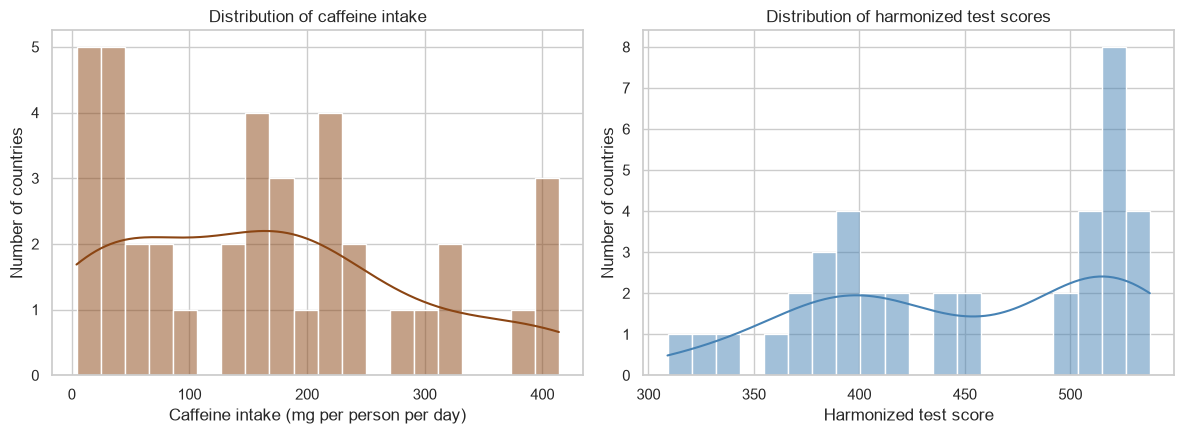

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df["caffeine_mg_per_day"], bins=20, kde=True, color="saddlebrown", ax=axes[0])
axes[0].set_title("Distribution of caffeine intake")
axes[0].set_xlabel("Caffeine intake (mg per person per day)")
axes[0].set_ylabel("Number of countries")

sns.histplot(df["test_score"].dropna(), bins=20, kde=True, color="steelblue", ax=axes[1])
axes[1].set_title("Distribution of harmonized test scores")
axes[1].set_xlabel("Harmonized test score")
axes[1].set_ylabel("Number of countries")

plt.tight_layout()
plt.savefig("figures/01_distributions.png", dpi=150)
plt.show()

**Plot 2.** Main relationship: caffeine intake vs test score with a regression line. The five biggest caffeine consumers are labeled.

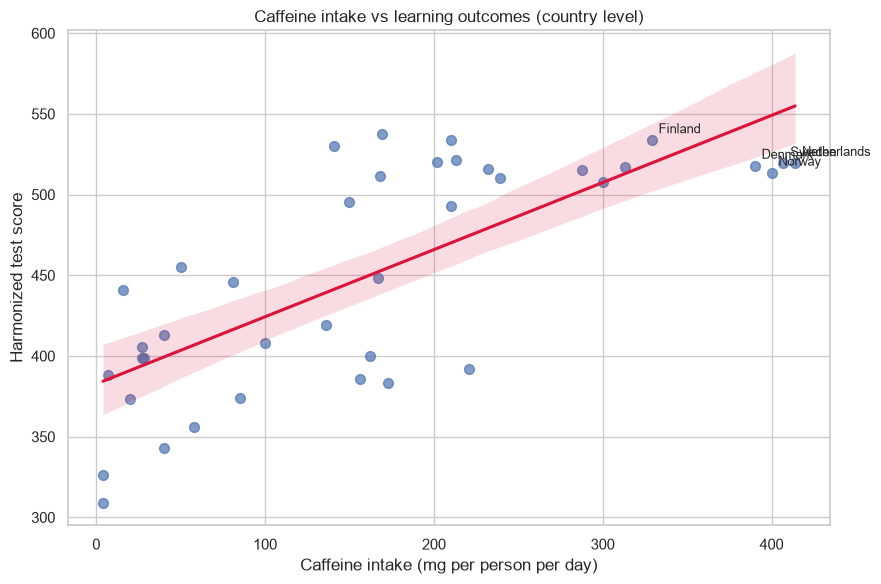

In [25]:
plot_df = df.dropna(subset=["caffeine_mg_per_day", "test_score"])

fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(data=plot_df, x="caffeine_mg_per_day", y="test_score",
            scatter_kws={"alpha": 0.7, "s": 50}, line_kws={"color": "crimson"}, ax=ax)

for _, row in plot_df.nlargest(5, "caffeine_mg_per_day").iterrows():
    ax.annotate(row["country"], (row["caffeine_mg_per_day"], row["test_score"]),
                textcoords="offset points", xytext=(5, 5), fontsize=9)

ax.set_title("Caffeine intake vs learning outcomes (country level)")
ax.set_xlabel("Caffeine intake (mg per person per day)")
ax.set_ylabel("Harmonized test score")
plt.tight_layout()
plt.savefig("figures/02_scatter_caffeine_vs_score.png", dpi=150)
plt.show()

**Plot 3.** Test scores by caffeine-intake tier (boxplot with individual countries).

/var/folders/lp/5kb7blq924b9j2c7r9srndnc0000gn/T/ipykernel_7740/3241282646.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df.dropna(subset=["test_score"]), x="caffeine_tier", y="test_score",


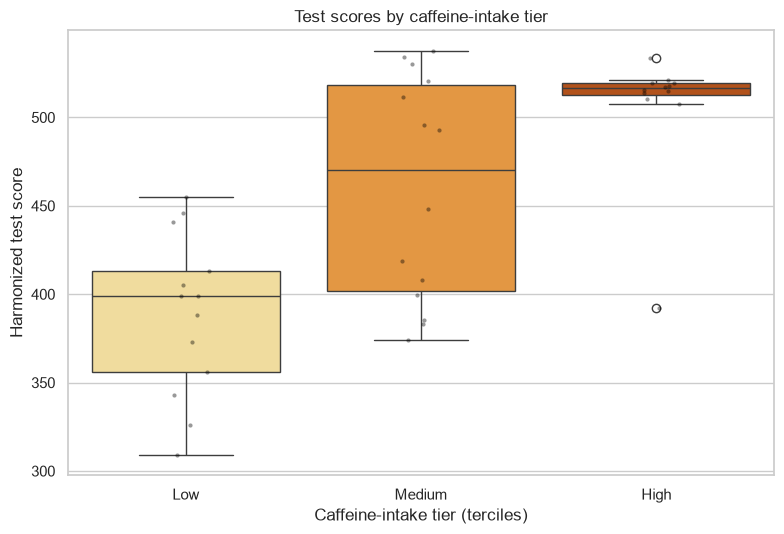

In [26]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.boxplot(data=df.dropna(subset=["test_score"]), x="caffeine_tier", y="test_score",
            order=["Low", "Medium", "High"], palette="YlOrBr", ax=ax)
sns.stripplot(data=df.dropna(subset=["test_score"]), x="caffeine_tier", y="test_score",
              order=["Low", "Medium", "High"], color="black", alpha=0.4, size=3, ax=ax)

ax.set_title("Test scores by caffeine-intake tier")
ax.set_xlabel("Caffeine-intake tier (terciles)")
ax.set_ylabel("Harmonized test score")
plt.tight_layout()
plt.savefig("figures/03_boxplot_tiers.png", dpi=150)
plt.show()

**Plot 4.** Correlation heatmap (Spearman) of all numeric variables.

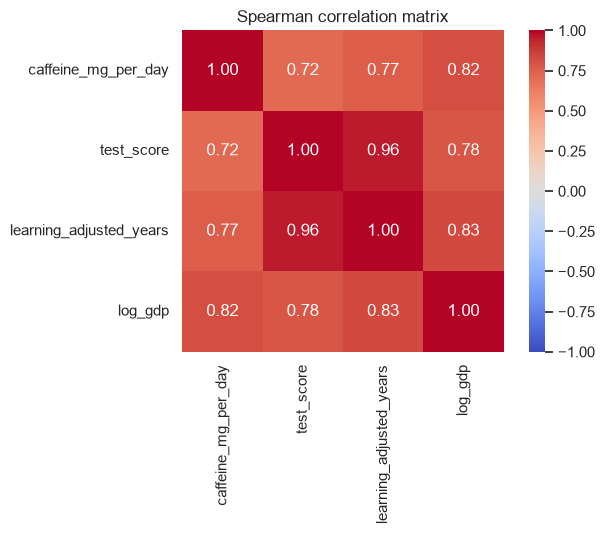

In [27]:
heat_vars = ["caffeine_mg_per_day", "test_score", "learning_adjusted_years", "log_gdp"]
corr_matrix = df[heat_vars].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation matrix")
plt.tight_layout()
plt.savefig("figures/04_correlation_heatmap.png", dpi=150)
plt.show()

**Plot 5.** The confounder: the same scatter plot colored by income level shows that wealth drives both variables.

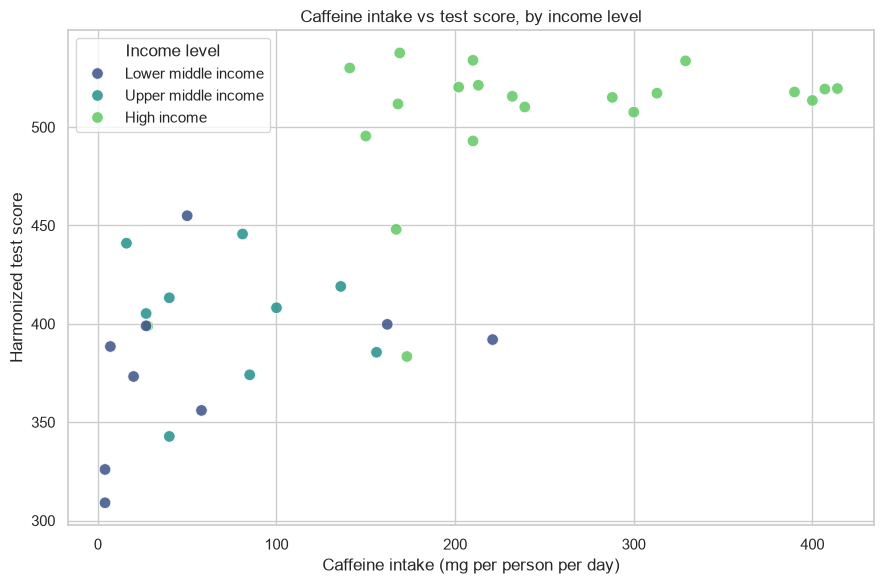

In [28]:
order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
plot_df = df.dropna(subset=["test_score"])

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="caffeine_mg_per_day", y="test_score", hue="income_level",
                hue_order=[o for o in order if o in plot_df["income_level"].unique()],
                palette="viridis", s=70, alpha=0.85, ax=ax)

ax.set_title("Caffeine intake vs test score, by income level")
ax.set_xlabel("Caffeine intake (mg per person per day)")
ax.set_ylabel("Harmonized test score")
ax.legend(title="Income level")
plt.tight_layout()
plt.savefig("figures/05_scatter_by_income.png", dpi=150)
plt.show()

## 7. Results and conclusions

Automatic summary of the key numbers (so the text always matches the results).

In [29]:
def strength(r):
    a = abs(r)
    return "negligible" if a < 0.1 else "weak" if a < 0.3 else "moderate" if a < 0.5 else "strong"


row = corr_res[corr_res["variable"] == "test_score"].iloc[0]
print(f"Countries analysed: {len(df)} (with test scores: {df['test_score'].notna().sum()})")
print(f"Caffeine vs test score: Pearson r = {row['pearson_r']:.2f} (p = {row['pearson_p']:.3f}), "
      f"Spearman rho = {row['spearman_rho']:.2f} -> {strength(row['pearson_r'])} "
      f"{'positive' if row['pearson_r'] > 0 else 'negative'} association")
print(f"After controlling for GDP: partial r = {r_part:.2f} (p = {p_part:.3f}) -> {strength(r_part)} association")

if abs(r_part) < abs(r_raw) * 0.6:
    print("Interpretation: most of the raw association disappears once wealth is controlled -> GDP is a strong confounder.")
else:
    print("Interpretation: the association stays noticeable after controlling for wealth.")

Countries analysed: 39 (with test scores: 39)
Caffeine vs test score: Pearson r = 0.74 (p = 0.000), Spearman rho = 0.72 -> strong positive association
After controlling for GDP: partial r = 0.31 (p = 0.058) -> moderate association
Interpretation: most of the raw association disappears once wealth is controlled -> GDP is a strong confounder.


### Key insights (fill in with the numbers printed above)
1. **Raw relationship:** countries with higher caffeine intake tend to have higher learning outcomes (see Plots 2 and 3).
2. **Confounding:** wealthy countries both consume more caffeine and invest more in education (Plots 4 and 5); the partial correlation shows how much of the link remains after controlling for GDP.
3. **Tier comparison:** the "High" caffeine tier has a higher average test score than the "Low" tier (see the tier table in Section 5).

### Limitations
- **Ecological fallacy:** country-level averages say nothing about whether *an individual student* studies better after drinking caffeine.
- **Old and small sample:** the caffeine data is from 1995, covers only about 40 countries and excludes energy drinks and soft drinks.
- **Different years:** caffeine intake (1995) and World Bank indicators (about 2017-2020) are decades apart, so we assume national habits are stable over time.
- **Correlation is not causation:** the data cannot show that caffeine improves study effectiveness.

### Possible extensions
- Compare the effect of coffee-based vs tea-based caffeine intake (both columns are already scraped).
- Use a student survey (individual-level data) on caffeine intake and grades.
- Fit a multiple regression with more controls (education spending, climate, region).

## Reproducibility
Run all cells top to bottom (`Kernel → Restart & Run All`). Required libraries (`requirements.txt`):
```
requests
beautifulsoup4
pandas
numpy
matplotlib
seaborn
scipy
```